In [176]:
import torch
from torch import nn, optim
import matplotlib.pyplot as plt
from cycler import cycler

from utils import *

# Apprendre à dessiner des cercles

Étant donné un nombre de points $N$, un rayon $r$ et un angle $θ$, on
peut obtenir les coordonnées de $N$ points uniformément répartis sur le cercle
de rayon $r$ en utilisant les formules suivantes : 

$$
x_i = r \cos\left(θ + \frac{2π i}{N}\right), \quad y_i = r \sin\left(θ + \frac{2π i}{N}\right)
$$

Pour $N$ fixé, nous allons essayer de faire apprendre ces formules à un réseau
de neurones. C'est à dire la fonction

$$
f_N(r, θ) = \begin{bmatrix}
r \cos(θ) & r \sin(θ) \\
⋮ & ⋮ \\
r \cos\left(θ + \frac{2π (N-1)}{N}\right) & r \sin\left(θ + \frac{2π (N-1)}{N}\right)
\end{bmatrix}
$$

Cette représentation présente cependant un problème, tous les angles $θ + 2kπ$
sont considérés comme différents. On va donc plutôt considérer $f_N(r, c, s)$ où
$c = \cos(θ)$ et $s = \sin(θ)$.

In [177]:
def make_data(n_samples, n_points):
    radius = torch.empty(n_samples); radius.uniform_(0.5, 5)
    theta = torch.empty(n_samples); theta.uniform_(0, 2 * torch.pi)
    inputs = torch.stack([radius, torch.cos(theta), torch.sin(theta)], dim=-1)

    angles = theta.view(-1, 1) + torch.linspace(0, 2 * torch.pi * (n_points - 1) / n_points, n_points)

    x = radius.view(-1, 1) * torch.cos(angles)
    y = radius.view(-1, 1) * torch.sin(angles)
    points = torch.stack([x, y], dim=-1)
    points += torch.randn_like(points) * 0.05 # add some noise

    return inputs, points

In [178]:
class CircleMaker(nn.Module):
    def __init__(self, nb_points, hidden_dim):
        super().__init__()
        self.nb_points = nb_points
        self.stack = nn.Sequential(
            nn.Linear(3, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2 * nb_points),
        )

    def forward(self, x):
        points = self.stack(x)
        return points.view(-1, self.nb_points, 2)

def criterion(predicted, target, radius):
    """Mean relative squared error between predicted and target points.

    It can be seen as the mean squared error where the distance between the
    predicted and target points is measured in units of the radius of the circle
    they belong to. This way a small deviation from a small circle is penalized
    more than the same deviation from a large circle.
    """
    relative_distance = (predicted - target) / radius.view(-1, 1, 1)
    relative_squared_error = relative_distance.square().sum(dim=-1)
    return relative_squared_error.mean()


In [179]:
def train(model: CircleMaker, data, epochs=10000, gd_lr=0.2, spec_index=None, spec_lr=0.2):
    """Train the model using gradient descent on every parameter and spectral
    gradient descent on the specified parameter.
    """
    print("Training model with specGD on parameter", spec_index)
    if spec_index is None:
        optimizers = [optim.SGD(model.parameters(), lr=gd_lr)]
    else:
        spectral_parameters, other_parameters = sort_parameters(model.parameters())
        spec_param = spectral_parameters.pop(spec_index)
        optimizers = [
            optim.SGD(other_parameters + spectral_parameters, lr=gd_lr),
            spectral_GD(spec_param, lr=spec_lr)
        ]

    losses = []
    inputs, targets = data
    radius = inputs[:, 0]
    for _ in range(epochs):
        predicted = model(inputs)
        loss = criterion(predicted, targets, radius)
        losses.append(loss.item())
        loss.backward()
        for optimizer in optimizers:
            optimizer.step()
            optimizer.zero_grad()
    return losses

In [180]:
n_points = 10
data = make_data(1000, n_points)

names = ("only GD", "stack.0.weight", "stack.2.weight", "stack.4.weight", "stack.6.weight")
models = [CircleMaker(n_points, hidden_dim=32) for _ in names]

In [181]:
losses = [
    train(model, data, gd_lr=0.3, spec_lr=0.0015, spec_index=None if i == 0 else i - 1)
    for i, model in enumerate(models)
]

for name, loss in zip(names, losses):
    print(f"Final loss for {name}:\t{loss[-1]}")

Training model with specGD on parameter None
Training model with specGD on parameter 0
Training model with specGD on parameter 1
Training model with specGD on parameter 2
Training model with specGD on parameter 3
Final loss for only GD:	0.00203018169850111
Final loss for stack.0.weight:	0.002078621182590723
Final loss for stack.2.weight:	0.0021091315429657698
Final loss for stack.4.weight:	0.001950142439454794
Final loss for stack.6.weight:	0.0019354225369170308


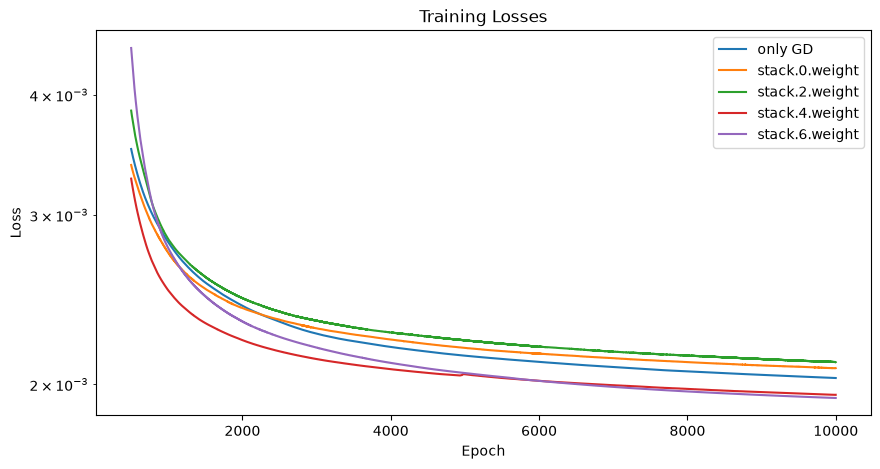

In [182]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.set_title("Training Losses")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_yscale("log")

for name, loss in zip(names, losses):
    ax.plot(range(500, len(loss)), loss[500:], label=name)
ax.legend()

plt.show()

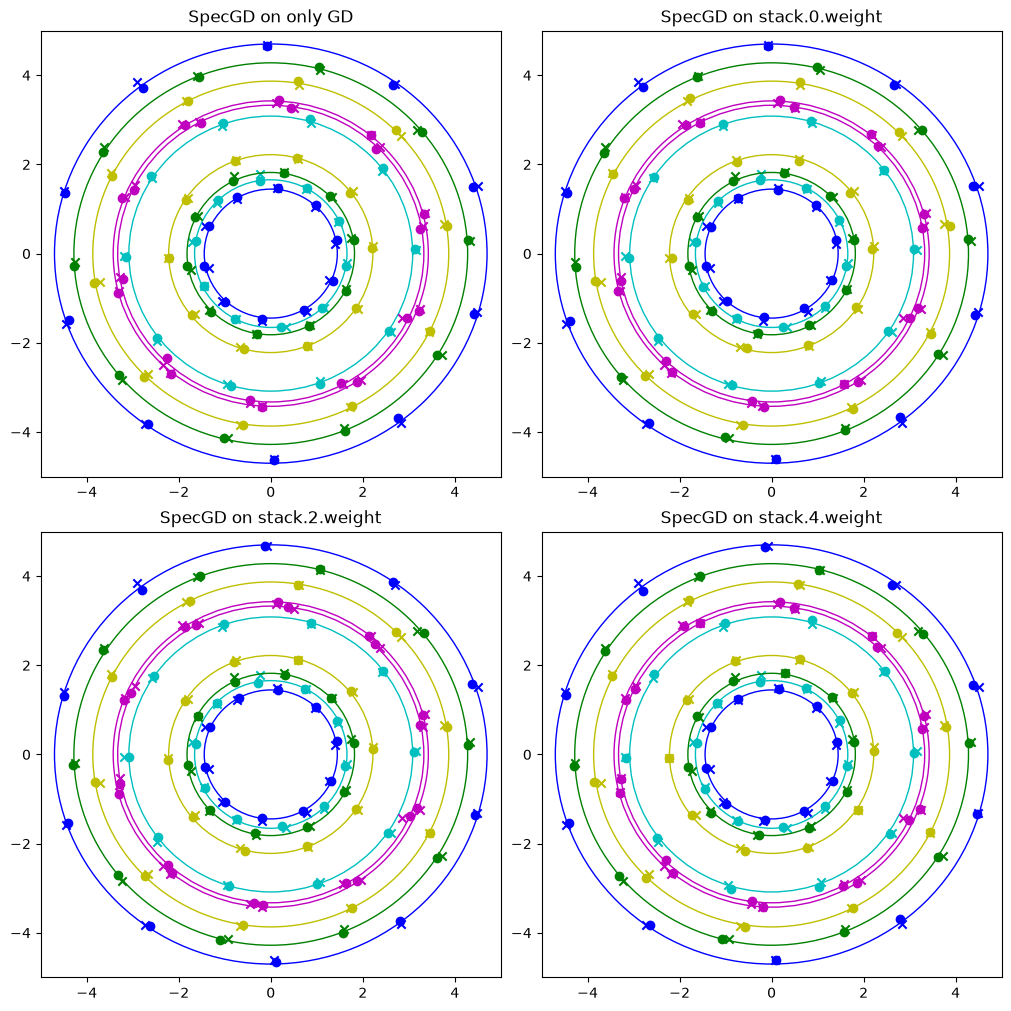

In [192]:
test_inputs, points = make_data(10, n_points)
radius = test_inputs[:, 0]

with torch.no_grad():
    predicted_points = [model(test_inputs) for model in models]

fig, axs = plt.subplots(2, 2, figsize=(10, 10), layout="constrained")
axs = axs.flatten()
colors = ['b', 'g', 'c', 'm', 'y'] * 2

for ax, name, prediction in zip(axs, names, predicted_points):
    ax.set_title(f'SpecGD on {str(name)}')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    for rad, circle, pred_circle, color in zip(radius, points, prediction, colors):
        ax.scatter(circle[:, 0], circle[:, 1], color=color, marker='x')
        ax.scatter(pred_circle[:, 0], pred_circle[:, 1], color=color)
        circle_artist = plt.Circle((0, 0), radius=rad, color=color, fill=False)
        ax.add_artist(circle_artist)

plt.show()